# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Rafa Rizki Aira Swala | 5054251017 |

## LINK HASIL DEPLOYMENT TUGAS 2
https://deploy-msit-aira.streamlit.app/

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Set random seed
torch.manual_seed(42)
np.random.seed(42)

# Tentukan device
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device yang digunakan:", device)

Device yang digunakan: cpu


In [2]:
# Load file CSV
train_df = pd.read_csv('MNIST DATASET/fashion-mnist_train.csv')
test_df = pd.read_csv('MNIST DATASET/fashion-mnist_test.csv')

# Tampilkan ukuran data
print("Ukuran data train:", train_df.shape)
print("Ukuran data test:", test_df.shape)

# Tampilkan 5 baris pertama
train_df.head()

Ukuran data train: (60000, 785)
Ukuran data test: (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


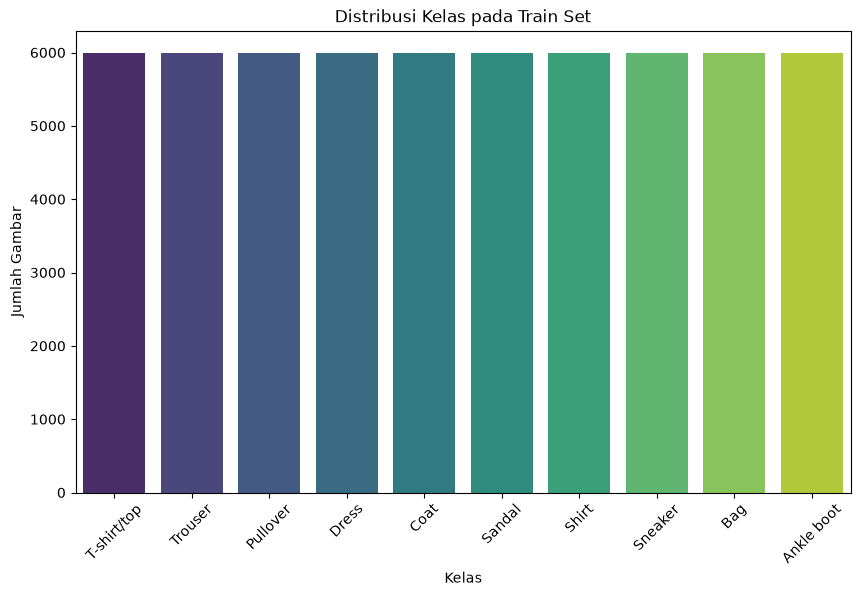

label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


In [9]:
class_names = {
    0: 'T-shirt/top',
    1: 'Trouser',
    2: 'Pullover',
    3: 'Dress',
    4: 'Coat',
    5: 'Sandal',
    6: 'Shirt',
    7: 'Sneaker',
    8: 'Bag',
    9: 'Ankle boot'
}

label_counts = train_df['label'].value_counts().sort_index()

plt.figure(figsize=(10, 6))
sns.barplot(
    x=[class_names[i] for i in label_counts.index],
    y=label_counts.values,
    hue=[class_names[i] for i in label_counts.index],
    palette='viridis',
    legend=False
)
plt.title('Distribusi Kelas pada Train Set')
plt.xlabel('Kelas')
plt.ylabel('Jumlah Gambar')
plt.xticks(rotation=45)
plt.show()

print(label_counts)

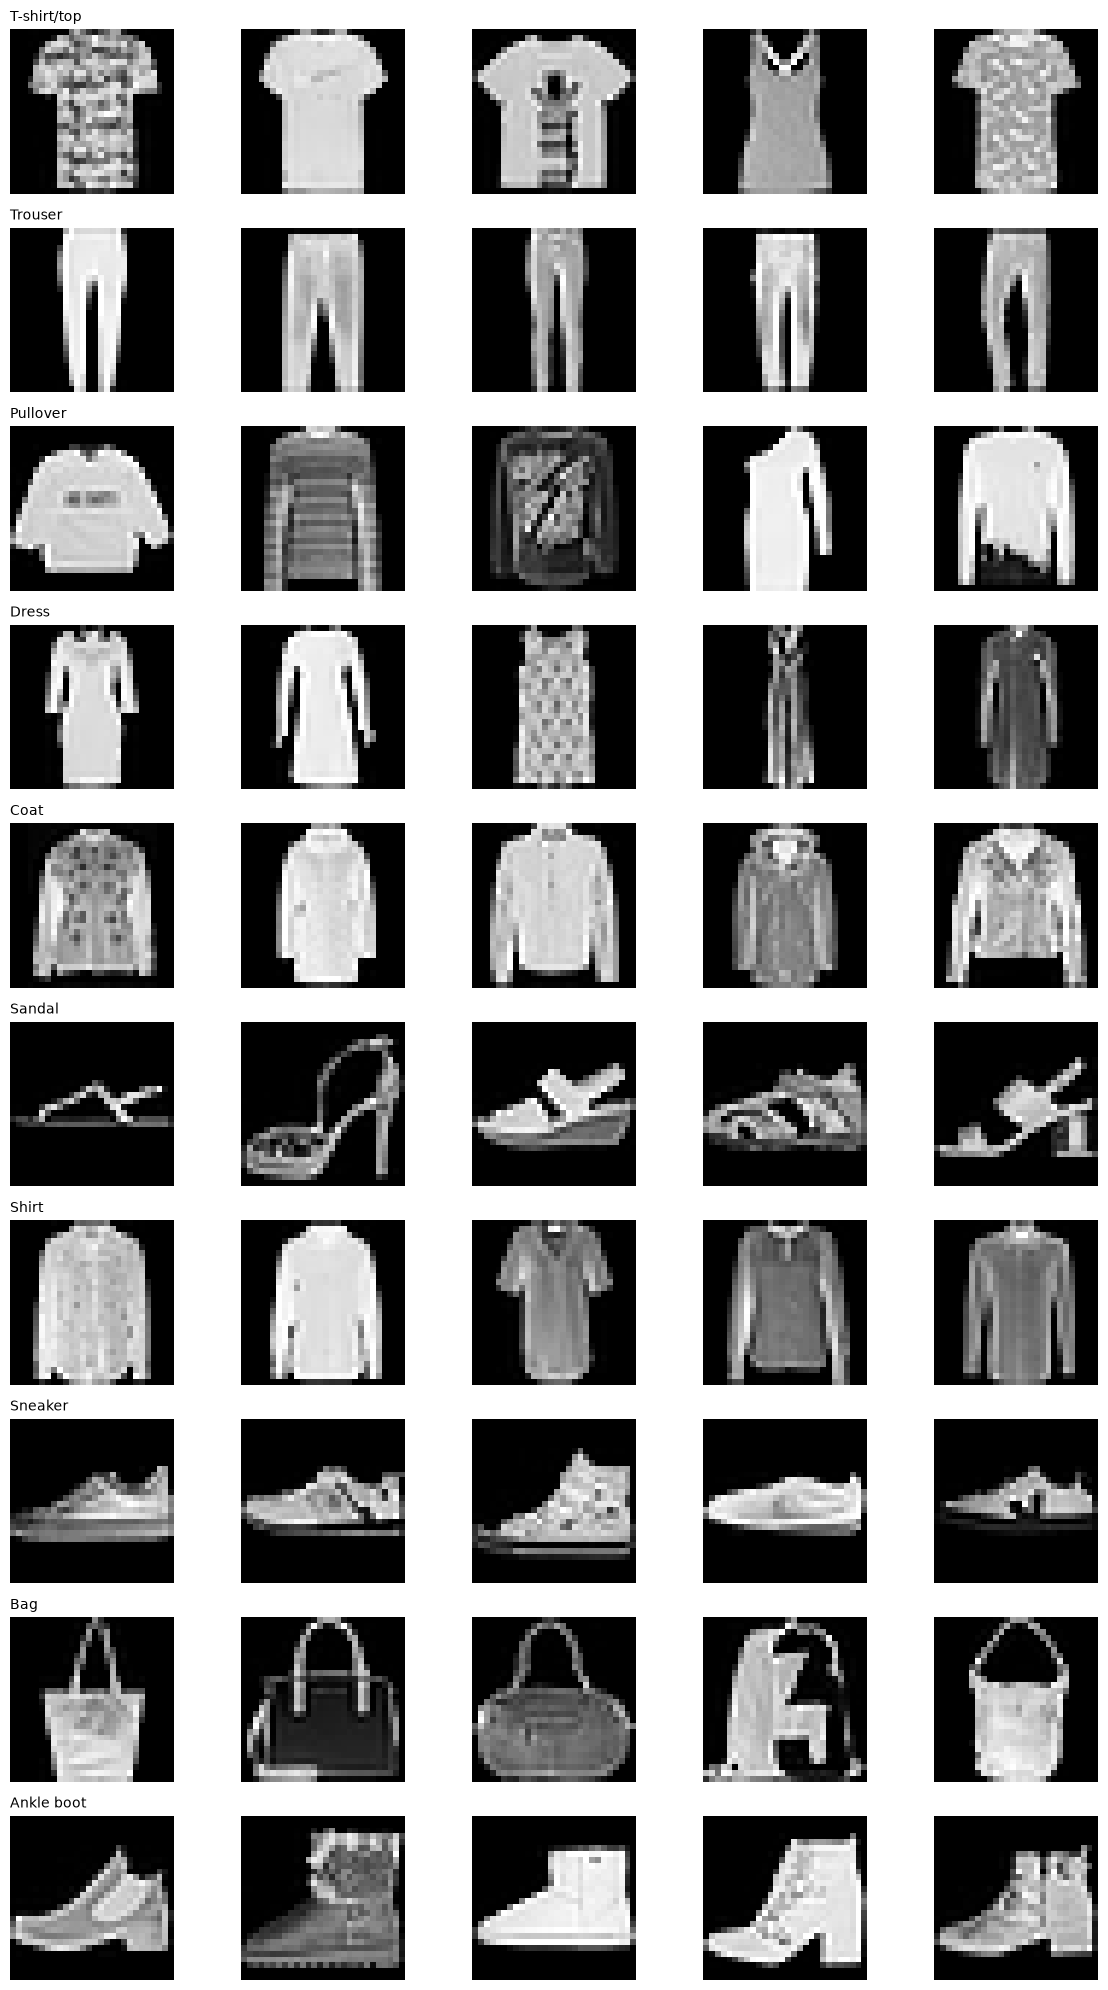

In [4]:
# Tampilkan grid 10 kelas x 5 gambar
fig, axes = plt.subplots(10, 5, figsize=(12, 20))

for label in range(10):
    # Ambil 5 gambar untuk setiap kelas
    samples = train_df[train_df['label'] == label].head(5)
    for idx, (_, row) in enumerate(samples.iterrows()):
        img = row.drop('label').values.reshape(28, 28)
        axes[label, idx].imshow(img, cmap='gray')
        axes[label, idx].axis('off')
        if idx == 0:
            axes[label, idx].set_title(class_names[label], fontsize=10, loc='left')

plt.tight_layout()
plt.show()

### Analisis Visual Kemiripan Kelas

Berdasarkan hasil visualisasi 5 sampel gambar untuk masing-masing dari 10 kelas, terlihat beberapa kelas yang secara visual memiliki kemiripan bentuk dan siluet, yaitu:

1. **T-shirt/top (0), Pullover (2), Shirt (6), dan Coat (4)**
   Keempat kelas ini merupakan pakaian atasan dengan bentuk siluet yang hampir seragam pada resolusi 28x28. Perbedaan detail seperti kerah, kancing, atau panjang lengan seringkali tidak terlihat jelas. Contohnya, Shirt (6) dan T-shirt/top (0) pada beberapa sampel tampak hampir identik, begitu pula Pullover (2) dengan Coat (4) yang samasama berlengan panjang dan berbadan lebar.

2. **Sneaker (7), Ankle boot (9), dan Sandal (5)**
   Kelompok alas kaki ini memiliki kemiripan siluet bawah yang menempel pada tanah. Sneaker (7) dan Ankle boot (9) paling sulit dibedakan karena keduanya merupakan sepatu tertutup, di mana perbedaan utamanya hanya pada tinggi bagian pergelangan kaki. Sementara Sandal (5) memiliki variasi bentuk yang besar (seperti high heels atau sandal jepit) namun pada beberapa sampel sandal tertutup bisa menyerupai sneaker.

3. **Trouser (1) dan Dress (3)**
   Trouser (1) dan Dress (3) memiliki bagian bawah yang berbentuk pipa lebar yang mirip. Pada sampel Dress (3) yang panjang dan tidak menunjukkan detail bagian atas secara jelas, siluetnya bisa menyerupai Trouser (1).

4. **Bag (8)**
   Kelas Bag (8) justru memiliki bentuk yang cukup khas dan berbeda dari kelas lainnya, sehingga secara visual paling mudah dibedakan.

Kemiripan visual antar kelas ini menjadi tantangan utama bagi model klasifikasi, di mana kesalahan prediksi (misclassification) kemungkinan besar akan terjadi di antara kelas-kelas yang serupa tersebut. Hal ini nantinya dapat dikonfirmasi melalui Confusion Matrix pada tahap evaluasi model.

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

Jumlah missing value pada train set: 0
Jumlah missing value pada test set: 0

Statistik nilai piksel data train:
Nilai minimum: 0
Nilai maksimum: 255
Rata-rata: 72.9568306122449
Standar deviasi: 89.9668629851211


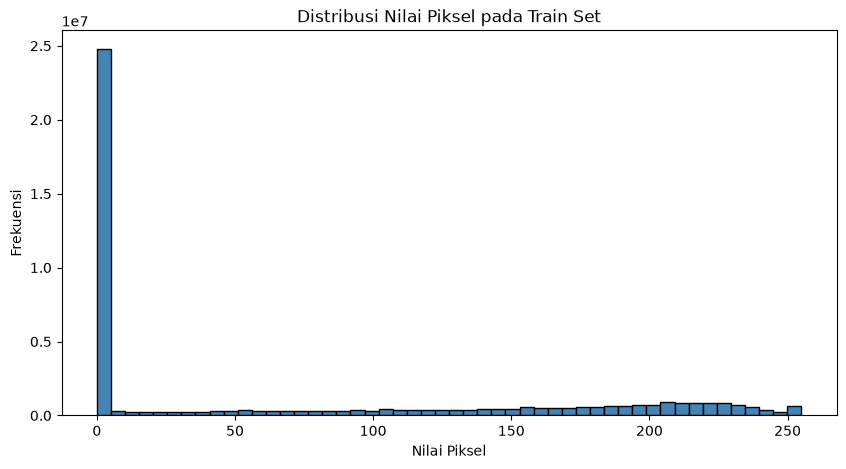

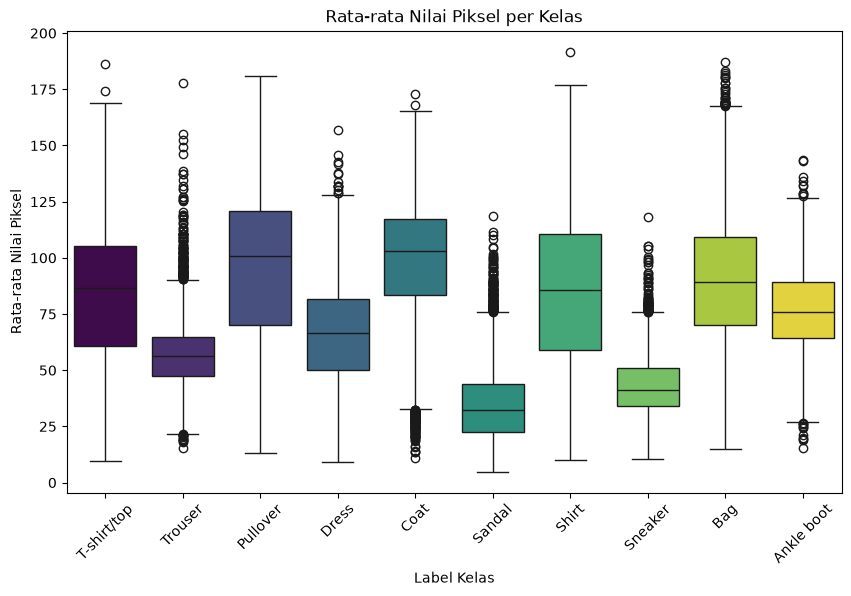

In [10]:
print("Jumlah missing value pada train set:", train_df.isnull().sum().sum())
print("Jumlah missing value pada test set:", test_df.isnull().sum().sum())

X_train_raw = train_df.drop('label', axis=1).values
print("\nStatistik nilai piksel data train:")
print("Nilai minimum:", X_train_raw.min())
print("Nilai maksimum:", X_train_raw.max())
print("Rata-rata:", X_train_raw.mean())
print("Standar deviasi:", X_train_raw.std())

plt.figure(figsize=(10, 5))
plt.hist(X_train_raw.flatten(), bins=50, color='steelblue', edgecolor='black')
plt.title('Distribusi Nilai Piksel pada Train Set')
plt.xlabel('Nilai Piksel')
plt.ylabel('Frekuensi')
plt.show()

train_df_copy = train_df.copy()
train_df_copy['mean_pixel'] = train_df_copy.drop('label', axis=1).mean(axis=1)

plt.figure(figsize=(10, 6))
sns.boxplot(
    x='label',
    y='mean_pixel',
    data=train_df_copy,
    hue='label',
    palette='viridis',
    legend=False
)
plt.title('Rata-rata Nilai Piksel per Kelas')
plt.xlabel('Label Kelas')
plt.ylabel('Rata-rata Nilai Piksel')
plt.xticks(ticks=range(10), labels=[class_names[i] for i in range(10)], rotation=45)
plt.show()

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [15]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test
X_train_full = train_df.drop('label', axis=1).values
y_train_full = train_df['label'].values

X_test = test_df.drop('label', axis=1).values
y_test = test_df['label'].values

print("Bentuk X_train_full:", X_train_full.shape)
print("Bentuk y_train_full:", y_train_full.shape)
print("Bentuk X_test:", X_test.shape)
print("Bentuk y_test:", y_test.shape)

Bentuk X_train_full: (60000, 784)
Bentuk y_train_full: (60000,)
Bentuk X_test: (10000, 784)
Bentuk y_test: (10000,)


In [16]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255)
X_train_full = X_train_full / 255.0
X_test = X_test / 255.0

print("Nilai minimum X_train_full:", X_train_full.min())
print("Nilai maksimum X_train_full:", X_train_full.max())
print("Nilai minimum X_test:", X_test.min())
print("Nilai maksimum X_test:", X_test.max())

Nilai minimum X_train_full: 0.0
Nilai maksimum X_train_full: 1.0
Nilai minimum X_test: 0.0
Nilai maksimum X_test: 1.0


In [17]:
from sklearn.model_selection import train_test_split

# Bagi data train menjadi train set dan validation set (90:10) dengan stratify=y
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.1,
    stratify=y_train_full,
    random_state=42
)

print("Bentuk X_train:", X_train.shape)
print("Bentuk X_val:", X_val.shape)
print("Bentuk X_test:", X_test.shape)

# Cek proporsi kelas tetap seimbang setelah split
print("\nProporsi kelas di train set:")
print(np.bincount(y_train) / len(y_train))
print("\nProporsi kelas di validation set:")
print(np.bincount(y_val) / len(y_val))

Bentuk X_train: (54000, 784)
Bentuk X_val: (6000, 784)
Bentuk X_test: (10000, 784)

Proporsi kelas di train set:
[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]

Proporsi kelas di validation set:
[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]


In [18]:
# Ubah data menjadi tensor
# X bertipe torch.float32 dengan bentuk (N, 1, 28, 28)
# y bertipe torch.long (wajib untuk nn.CrossEntropyLoss)
X_train_tensor = torch.tensor(X_train, dtype=torch.float32).view(-1, 1, 28, 28)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32).view(-1, 1, 28, 28)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32).view(-1, 1, 28, 28)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("Bentuk X_train_tensor:", X_train_tensor.shape, "| dtype:", X_train_tensor.dtype)
print("Bentuk y_train_tensor:", y_train_tensor.shape, "| dtype:", y_train_tensor.dtype)
print("Bentuk X_val_tensor:", X_val_tensor.shape, "| dtype:", X_val_tensor.dtype)
print("Bentuk y_val_tensor:", y_val_tensor.shape, "| dtype:", y_val_tensor.dtype)
print("Bentuk X_test_tensor:", X_test_tensor.shape, "| dtype:", X_test_tensor.dtype)
print("Bentuk y_test_tensor:", y_test_tensor.shape, "| dtype:", y_test_tensor.dtype)

Bentuk X_train_tensor: torch.Size([54000, 1, 28, 28]) | dtype: torch.float32
Bentuk y_train_tensor: torch.Size([54000]) | dtype: torch.int64
Bentuk X_val_tensor: torch.Size([6000, 1, 28, 28]) | dtype: torch.float32
Bentuk y_val_tensor: torch.Size([6000]) | dtype: torch.int64
Bentuk X_test_tensor: torch.Size([10000, 1, 28, 28]) | dtype: torch.float32
Bentuk y_test_tensor: torch.Size([10000]) | dtype: torch.int64


In [19]:
from torch.utils.data import TensorDataset, DataLoader

# Buat TensorDataset
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Buat DataLoader (shuffle=True hanya untuk train)
BATCH_SIZE = 64

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Jumlah batch train:", len(train_loader))
print("Jumlah batch validation:", len(val_loader))
print("Jumlah batch test:", len(test_loader))

Jumlah batch train: 844
Jumlah batch validation: 94
Jumlah batch test: 157


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [20]:
import torch.nn as nn

class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

# Inisialisasi model dan pindahkan ke device
ann_model = ANN().to(device)

# Tampilkan arsitektur dan jumlah parameter
print(ann_model)
total_params = sum(p.numel() for p in ann_model.parameters())
print("\nJumlah parameter ANN:", total_params)

ANN(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
)

Jumlah parameter ANN: 235146


In [21]:
import copy

# Hyperparameter
LEARNING_RATE = 0.001
EPOCHS = 10

criterion = nn.CrossEntropyLoss()

def train_model(model, train_loader, val_loader, criterion, optimizer, epochs, device):
    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': []
    }
    best_val_acc = 0.0
    best_model_state = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        # Training phase
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            outputs = model(x)
            loss = criterion(outputs, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * x.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == y).sum().item()
            total += y.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        # Validation phase
        model.eval()
        val_running_loss = 0.0
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                outputs = model(x)
                loss = criterion(outputs, y)
                val_running_loss += loss.item() * x.size(0)
                _, predicted = torch.max(outputs, 1)
                val_correct += (predicted == y).sum().item()
                val_total += y.size(0)

        val_loss = val_running_loss / val_total
        val_acc = val_correct / val_total

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        # Simpan model terbaik berdasarkan val accuracy
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_state = copy.deepcopy(model.state_dict())

        print(f"Epoch {epoch+1}/{epochs} | "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

    # Kembalikan model terbaik
    model.load_state_dict(best_model_state)
    print(f"\nBest Validation Accuracy: {best_val_acc:.4f}")
    return history

In [22]:
# Optimizer
optimizer_ann = torch.optim.Adam(ann_model.parameters(), lr=LEARNING_RATE)

# Train
ann_history = train_model(
    ann_model,
    train_loader,
    val_loader,
    criterion,
    optimizer_ann,
    EPOCHS,
    device
)

Epoch 1/10 | Train Loss: 0.5420 | Train Acc: 0.8069 | Val Loss: 0.4273 | Val Acc: 0.8407
Epoch 2/10 | Train Loss: 0.3827 | Train Acc: 0.8598 | Val Loss: 0.4057 | Val Acc: 0.8528
Epoch 3/10 | Train Loss: 0.3456 | Train Acc: 0.8748 | Val Loss: 0.3666 | Val Acc: 0.8678
Epoch 4/10 | Train Loss: 0.3193 | Train Acc: 0.8828 | Val Loss: 0.3993 | Val Acc: 0.8560
Epoch 5/10 | Train Loss: 0.2988 | Train Acc: 0.8891 | Val Loss: 0.3260 | Val Acc: 0.8818
Epoch 6/10 | Train Loss: 0.2853 | Train Acc: 0.8939 | Val Loss: 0.3282 | Val Acc: 0.8847
Epoch 7/10 | Train Loss: 0.2702 | Train Acc: 0.9002 | Val Loss: 0.3224 | Val Acc: 0.8857
Epoch 8/10 | Train Loss: 0.2563 | Train Acc: 0.9040 | Val Loss: 0.3198 | Val Acc: 0.8818
Epoch 9/10 | Train Loss: 0.2470 | Train Acc: 0.9079 | Val Loss: 0.3111 | Val Acc: 0.8862
Epoch 10/10 | Train Loss: 0.2352 | Train Acc: 0.9121 | Val Loss: 0.3400 | Val Acc: 0.8750

Best Validation Accuracy: 0.8862


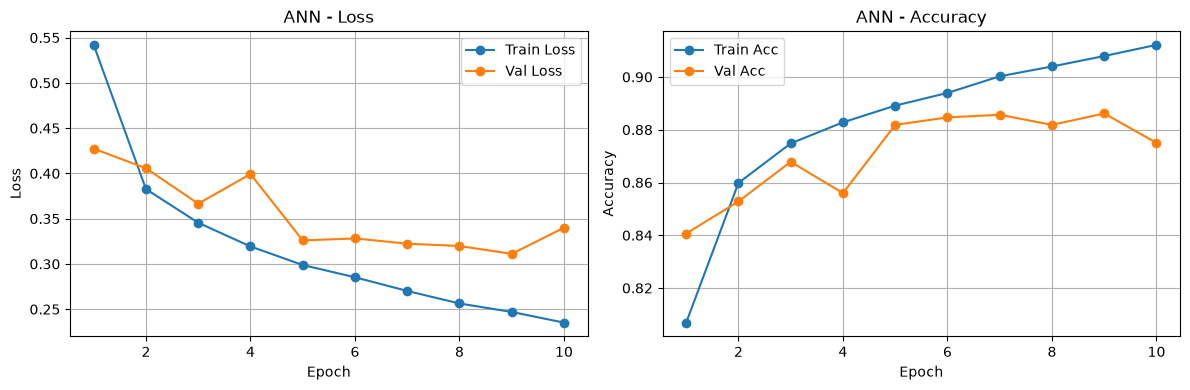

In [24]:
import matplotlib.pyplot as plt

def plot_history(history, title="Learning Curve"):
    epochs_range = range(1, len(history['train_loss']) + 1)

    plt.figure(figsize=(12, 4))

    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history['train_loss'], label='Train Loss', marker='o')
    plt.plot(epochs_range, history['val_loss'], label='Val Loss', marker='o')
    plt.title(f'{title} - Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # Plot Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, history['train_acc'], label='Train Acc', marker='o')
    plt.plot(epochs_range, history['val_acc'], label='Val Acc', marker='o')
    plt.title(f'{title} - Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

# Tampilkan learning curve ANN
plot_history(ann_history, title="ANN")

In [25]:
# Prediksi pada test set
ann_model.eval()
ann_preds = []
ann_true = []

with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        outputs = ann_model(x)
        _, predicted = torch.max(outputs, 1)
        ann_preds.extend(predicted.cpu().numpy())
        ann_true.extend(y.cpu().numpy())

# Simpan dalam bentuk numpy array
ann_preds = np.array(ann_preds)
ann_true = np.array(ann_true)

print("Bentuk ann_preds:", ann_preds.shape)
print("Bentuk ann_true:", ann_true.shape)
print("\nContoh 10 prediksi pertama:", ann_preds[:10])
print("Contoh 10 label asli pertama:", ann_true[:10])

Bentuk ann_preds: (10000,)
Bentuk ann_true: (10000,)

Contoh 10 prediksi pertama: [0 1 2 2 4 6 8 2 5 0]
Contoh 10 label asli pertama: [0 1 2 2 3 2 8 6 5 0]


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [26]:
# Rumus: output_size = (W - K + 2P) / S + 1
# Input awal: 28 x 28, channel 1

# Blok 1
# Conv2d(1, 32, kernel_size=3, padding=1, stride=1)
# W = 28, K = 3, P = 1, S = 1 -> (28 - 3 + 2*1)/1 + 1 = 28
conv1_out = (28 - 3 + 2 * 1) // 1 + 1
# MaxPool2d(2) -> (28 - 2)/2 + 1 = 14
pool1_out = (conv1_out - 2) // 2 + 1

# Blok 2
# Conv2d(32, 64, kernel_size=3, padding=1, stride=1)
# W = 14, K = 3, P = 1, S = 1 -> (14 - 3 + 2*1)/1 + 1 = 14
conv2_out = (pool1_out - 3 + 2 * 1) // 1 + 1
# MaxPool2d(2) -> (14 - 2)/2 + 1 = 7
pool2_out = (conv2_out - 2) // 2 + 1

print("Ukuran output Blok 1 (setelah Conv + Pool):", pool1_out, "x", pool1_out)
print("Ukuran output Blok 2 (setelah Conv + Pool):", pool2_out, "x", pool2_out)
print(f"\nUkuran input nn.Linear pertama setelah Flatten: {64} x {pool2_out} x {pool2_out} = {64 * pool2_out * pool2_out}")

Ukuran output Blok 1 (setelah Conv + Pool): 14 x 14
Ukuran output Blok 2 (setelah Conv + Pool): 7 x 7

Ukuran input nn.Linear pertama setelah Flatten: 64 x 7 x 7 = 3136


In [27]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        # Blok konvolusi 1: Conv2d -> ReLU -> MaxPool2d
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)

        # Blok konvolusi 2: Conv2d -> ReLU -> MaxPool2d
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)

        # Bagian klasifikasi
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)
        return x

# Inisialisasi model dan pindahkan ke device
cnn_model = SimpleCNN().to(device)

# Tampilkan arsitektur dan jumlah parameter
print(cnn_model)
total_params = sum(p.numel() for p in cnn_model.parameters())
print("\nJumlah parameter CNN Sederhana:", total_params)

SimpleCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

Jumlah parameter CNN Sederhana: 421642


In [28]:
# Kirim tensor dummy ke bagian konvolusi untuk memverifikasi ukuran
dummy = torch.zeros(1, 1, 28, 28).to(device)

with torch.no_grad():
    out = cnn_model.conv1(dummy)
    print("Setelah conv1:", out.shape)
    out = cnn_model.pool1(cnn_model.relu1(out))
    print("Setelah pool1:", out.shape)
    out = cnn_model.conv2(out)
    print("Setelah conv2:", out.shape)
    out = cnn_model.pool2(cnn_model.relu2(out))
    print("Setelah pool2:", out.shape)
    out = cnn_model.flatten(out)
    print("Setelah flatten:", out.shape)

Setelah conv1: torch.Size([1, 32, 28, 28])
Setelah pool1: torch.Size([1, 32, 14, 14])
Setelah conv2: torch.Size([1, 64, 14, 14])
Setelah pool2: torch.Size([1, 64, 7, 7])
Setelah flatten: torch.Size([1, 3136])


In [29]:
# Optimizer dengan learning rate yang sama seperti 3.1
optimizer_cnn = torch.optim.Adam(cnn_model.parameters(), lr=LEARNING_RATE)

# Train
cnn_history = train_model(
    cnn_model,
    train_loader,
    val_loader,
    criterion,
    optimizer_cnn,
    EPOCHS,
    device
)

Epoch 1/10 | Train Loss: 0.4702 | Train Acc: 0.8305 | Val Loss: 0.3484 | Val Acc: 0.8737
Epoch 2/10 | Train Loss: 0.3034 | Train Acc: 0.8903 | Val Loss: 0.2877 | Val Acc: 0.8973
Epoch 3/10 | Train Loss: 0.2554 | Train Acc: 0.9077 | Val Loss: 0.2638 | Val Acc: 0.9030
Epoch 4/10 | Train Loss: 0.2234 | Train Acc: 0.9179 | Val Loss: 0.2338 | Val Acc: 0.9132
Epoch 5/10 | Train Loss: 0.1961 | Train Acc: 0.9275 | Val Loss: 0.2411 | Val Acc: 0.9057
Epoch 6/10 | Train Loss: 0.1735 | Train Acc: 0.9357 | Val Loss: 0.2278 | Val Acc: 0.9200
Epoch 7/10 | Train Loss: 0.1554 | Train Acc: 0.9422 | Val Loss: 0.2527 | Val Acc: 0.9075
Epoch 8/10 | Train Loss: 0.1347 | Train Acc: 0.9504 | Val Loss: 0.2432 | Val Acc: 0.9140
Epoch 9/10 | Train Loss: 0.1184 | Train Acc: 0.9561 | Val Loss: 0.2254 | Val Acc: 0.9240
Epoch 10/10 | Train Loss: 0.1021 | Train Acc: 0.9623 | Val Loss: 0.2373 | Val Acc: 0.9207

Best Validation Accuracy: 0.9240


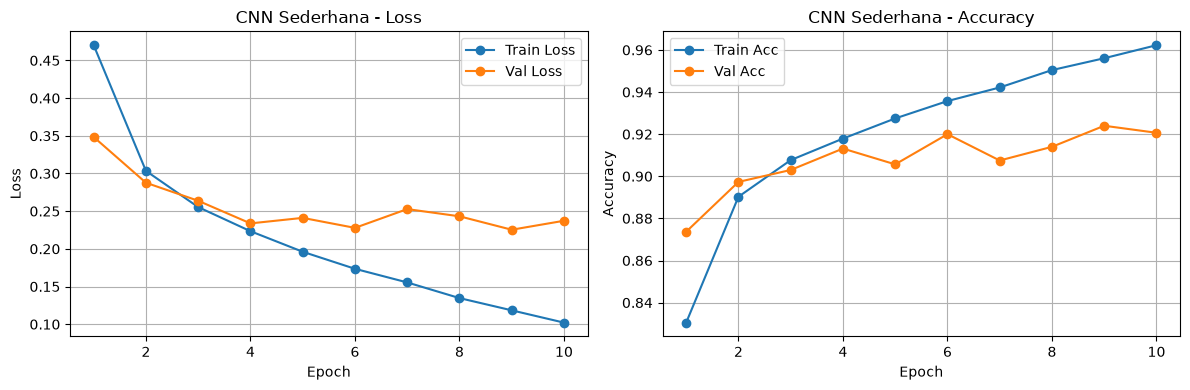

In [30]:
plot_history(cnn_history, title="CNN Sederhana")

In [31]:
cnn_model.eval()
cnn_preds = []
cnn_true = []

with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        outputs = cnn_model(x)
        _, predicted = torch.max(outputs, 1)
        cnn_preds.extend(predicted.cpu().numpy())
        cnn_true.extend(y.cpu().numpy())

cnn_preds = np.array(cnn_preds)
cnn_true = np.array(cnn_true)

print("Bentuk cnn_preds:", cnn_preds.shape)
print("Bentuk cnn_true:", cnn_true.shape)
print("\nContoh 10 prediksi pertama:", cnn_preds[:10])
print("Contoh 10 label asli pertama:", cnn_true[:10])

Bentuk cnn_preds: (10000,)
Bentuk cnn_true: (10000,)

Contoh 10 prediksi pertama: [0 1 2 2 3 6 8 2 5 0]
Contoh 10 label asli pertama: [0 1 2 2 3 2 8 6 5 0]


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [32]:
class CNNWithBN(nn.Module):
    def __init__(self, dropout_p=0.5):
        super(CNNWithBN, self).__init__()
        # Blok konvolusi 1: Conv2d -> BatchNorm2d -> ReLU -> MaxPool2d
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)

        # Blok konvolusi 2: Conv2d -> BatchNorm2d -> ReLU -> MaxPool2d
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)

        # Bagian klasifikasi
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(p=dropout_p)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.bn1(self.conv1(x))))
        x = self.pool2(self.relu2(self.bn2(self.conv2(x))))
        x = self.flatten(x)
        x = self.relu3(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Inisialisasi model dan pindahkan ke device
cnn_bn_model = CNNWithBN(dropout_p=0.5).to(device)

# Tampilkan arsitektur dan jumlah parameter
print(cnn_bn_model)
total_params = sum(p.numel() for p in cnn_bn_model.parameters())
print("\nJumlah parameter CNN dengan BN dan Dropout:", total_params)

CNNWithBN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

Jumlah parameter CNN dengan BN dan Dropout: 421834


In [33]:
dummy = torch.zeros(1, 1, 28, 28).to(device)

cnn_bn_model.eval()
with torch.no_grad():
    out = cnn_bn_model.conv1(dummy)
    print("Setelah conv1:", out.shape)
    out = cnn_bn_model.pool1(cnn_bn_model.relu1(cnn_bn_model.bn1(out)))
    print("Setelah pool1:", out.shape)
    out = cnn_bn_model.conv2(out)
    print("Setelah conv2:", out.shape)
    out = cnn_bn_model.pool2(cnn_bn_model.relu2(cnn_bn_model.bn2(out)))
    print("Setelah pool2:", out.shape)
    out = cnn_bn_model.flatten(out)
    print("Setelah flatten:", out.shape)

Setelah conv1: torch.Size([1, 32, 28, 28])
Setelah pool1: torch.Size([1, 32, 14, 14])
Setelah conv2: torch.Size([1, 64, 14, 14])
Setelah pool2: torch.Size([1, 64, 7, 7])
Setelah flatten: torch.Size([1, 3136])


In [34]:
# Optimizer dengan learning rate yang sama seperti 3.1 dan 3.2
optimizer_bn = torch.optim.Adam(cnn_bn_model.parameters(), lr=LEARNING_RATE)

# Train
cnn_bn_history = train_model(
    cnn_bn_model,
    train_loader,
    val_loader,
    criterion,
    optimizer_bn,
    EPOCHS,
    device
)

Epoch 1/10 | Train Loss: 0.5075 | Train Acc: 0.8192 | Val Loss: 0.3169 | Val Acc: 0.8832
Epoch 2/10 | Train Loss: 0.3590 | Train Acc: 0.8712 | Val Loss: 0.3062 | Val Acc: 0.8840
Epoch 3/10 | Train Loss: 0.3144 | Train Acc: 0.8879 | Val Loss: 0.2647 | Val Acc: 0.9062
Epoch 4/10 | Train Loss: 0.2842 | Train Acc: 0.8972 | Val Loss: 0.2419 | Val Acc: 0.9163
Epoch 5/10 | Train Loss: 0.2627 | Train Acc: 0.9066 | Val Loss: 0.2412 | Val Acc: 0.9122
Epoch 6/10 | Train Loss: 0.2442 | Train Acc: 0.9121 | Val Loss: 0.2480 | Val Acc: 0.9068
Epoch 7/10 | Train Loss: 0.2311 | Train Acc: 0.9161 | Val Loss: 0.2234 | Val Acc: 0.9183
Epoch 8/10 | Train Loss: 0.2165 | Train Acc: 0.9204 | Val Loss: 0.2320 | Val Acc: 0.9177
Epoch 9/10 | Train Loss: 0.2011 | Train Acc: 0.9261 | Val Loss: 0.2235 | Val Acc: 0.9213
Epoch 10/10 | Train Loss: 0.1926 | Train Acc: 0.9269 | Val Loss: 0.2536 | Val Acc: 0.9127

Best Validation Accuracy: 0.9213


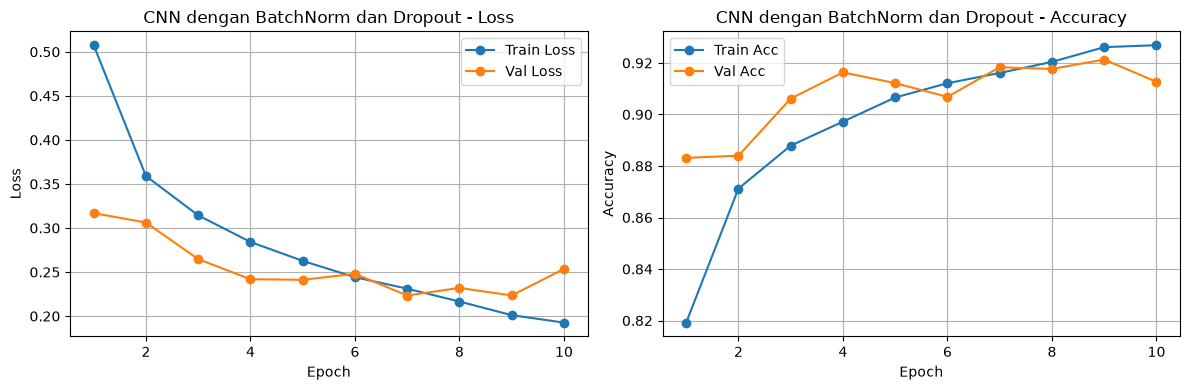

In [35]:
plot_history(cnn_bn_history, title="CNN dengan BatchNorm dan Dropout")

In [36]:
cnn_bn_model.eval()
cnn_bn_preds = []
cnn_bn_true = []

with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        outputs = cnn_bn_model(x)
        _, predicted = torch.max(outputs, 1)
        cnn_bn_preds.extend(predicted.cpu().numpy())
        cnn_bn_true.extend(y.cpu().numpy())

cnn_bn_preds = np.array(cnn_bn_preds)
cnn_bn_true = np.array(cnn_bn_true)

print("Bentuk cnn_bn_preds:", cnn_bn_preds.shape)
print("Bentuk cnn_bn_true:", cnn_bn_true.shape)
print("\nContoh 10 prediksi pertama:", cnn_bn_preds[:10])
print("Contoh 10 label asli pertama:", cnn_bn_true[:10])

Bentuk cnn_bn_preds: (10000,)
Bentuk cnn_bn_true: (10000,)

Contoh 10 prediksi pertama: [0 1 2 2 3 6 8 6 5 0]
Contoh 10 label asli pertama: [0 1 2 2 3 2 8 6 5 0]


## Perbandingan CNN Sederhana (3.2) dan CNN dengan BatchNorm + Dropout (3.3)

Berikut perbandingan berdasarkan hasil training yang diperoleh.

### Tabel Perbandingan

| Metrik | CNN Sederhana (3.2) | CNN + BN + Dropout (3.3) |
|---|---|---|
| Best Val Accuracy | 0.9240 (epoch 9) | 0.9213 (epoch 9) |
| Train Acc epoch terakhir | 0.9623 | 0.9269 |
| Val Acc epoch terakhir | 0.9207 | 0.9127 |
| Selisih Train - Val (epoch terakhir) | 0.0416 | 0.0142 |
| Train Loss epoch terakhir | 0.1021 | 0.1926 |
| Val Loss epoch terakhir | 0.2373 | 0.2536 |
| Val Loss terendah | 0.2254 (epoch 9) | 0.2234 (epoch 7) |

### Analisis Selisih Train dan Validation

1. **CNN Sederhana (3.2) memiliki selisih train dan validation yang jauh lebih besar.** Di epoch terakhir, train accuracy mencapai 0.9623 sedangkan val accuracy hanya 0.9207, selisih sekitar 4.16 persen. Train loss turun sangat tajam sampai 0.1021, sementara val loss justru naik dari 0.2254 di epoch 9 menjadi 0.2373 di epoch 10. Pola ini merupakan indikasi overfitting yang jelas: model semakin hafal data train tetapi tidak lagi meningkatkan performa di data validasi.

2. **CNN dengan BatchNorm dan Dropout (3.3) memiliki selisih train dan validation yang jauh lebih kecil.** Di epoch terakhir, train accuracy 0.9269 dan val accuracy 0.9127, selisih hanya sekitar 1.42 persen. Train loss tidak turun sedrastis model 3.2, yaitu berhenti di 0.1926. Ini menunjukkan bahwa BatchNorm dan Dropout berhasil menahan model agar tidak terlalu cepat menghafal data train.

3. **Namun, best val accuracy kedua model hampir setara.** Model 3.2 mencapai 0.9240 dan model 3.3 mencapai 0.9213, selisih hanya 0.0027 atau sekitar 0.27 persen. Artinya, pada dataset ini dan dengan 10 epoch, regularisasi di model 3.3 belum memberikan peningkatan akurasi validasi yang signifikan dibanding model 3.2. Yang jelas berbeda adalah tingkat overfitting-nya.

4. **Model 3.3 lebih stabil di sepanjang epoch.** Val accuracy model 3.3 bergerak di rentang 0.8832 sampai 0.9213 tanpa penurunan tajam, sedangkan model 3.2 sempat turun ke 0.9057 di epoch 5 dan 0.9075 di epoch 7 sebelum naik lagi. Val loss model 3.3 juga relatif lebih terkendali.

### Kesimpulan Perbandingan

Berdasarkan angka di atas, BatchNorm dan Dropout berhasil menekan overfitting secara nyata, terlihat dari selisih train dan validation yang mengecil dari sekitar 4.16 persen menjadi sekitar 1.42 persen. Akan tetapi, pada konfigurasi 10 epoch ini, peningkatan akurasi validasi terbaik belum signifikan, yaitu 0.9240 menjadi 0.9213. Dengan kata lain, model 3.2 masih sedikit lebih unggul dalam hal best val accuracy, tetapi model 3.3 lebih sehat dari sisi generalisasi karena jarak train dan validation yang lebih kecil. Jika jumlah epoch ditambah, model 3.2 kemungkinan akan semakin overfit, sedangkan model 3.3 berpotensi lebih stabil.

# 4. Evaluasi Model

In [37]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def compute_metrics(y_true, y_pred, model_name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    return {
        'Model': model_name,
        'Accuracy': acc,
        'Precision (macro)': prec,
        'Recall (macro)': rec,
        'F1-Score (macro)': f1
    }

In [38]:
# Hitung metrik untuk ketiga model
ann_metrics = compute_metrics(ann_true, ann_preds, 'ANN (3.1)')
cnn_metrics = compute_metrics(cnn_true, cnn_preds, 'CNN Sederhana (3.2)')
cnn_bn_metrics = compute_metrics(cnn_bn_true, cnn_bn_preds, 'CNN + BN + Dropout (3.3)')

# Jumlah parameter masing-masing model
ann_params = sum(p.numel() for p in ann_model.parameters())
cnn_params = sum(p.numel() for p in cnn_model.parameters())
cnn_bn_params = sum(p.numel() for p in cnn_bn_model.parameters())

ann_metrics['Jumlah Parameter'] = ann_params
cnn_metrics['Jumlah Parameter'] = cnn_params
cnn_bn_metrics['Jumlah Parameter'] = cnn_bn_params

# Susun menjadi DataFrame
comparison_df = pd.DataFrame([ann_metrics, cnn_metrics, cnn_bn_metrics])
comparison_df = comparison_df.set_index('Model')

# Tampilkan
pd.set_option('display.float_format', lambda x: f'{x:.4f}' if isinstance(x, float) else x)
print(comparison_df)

                          Accuracy  Precision (macro)  Recall (macro)  \
Model                                                                   
ANN (3.1)                   0.8879             0.8887          0.8879   
CNN Sederhana (3.2)         0.9268             0.9270          0.9268   
CNN + BN + Dropout (3.3)    0.9254             0.9266          0.9254   

                          F1-Score (macro)  Jumlah Parameter  
Model                                                         
ANN (3.1)                           0.8874            235146  
CNN Sederhana (3.2)                 0.9264            421642  
CNN + BN + Dropout (3.3)            0.9257            421834  


In [39]:
# Model terbaik ditentukan dari best val accuracy yang kamu laporkan
# ANN: tidak dilaporkan best val accuracy di output yang dikirim, tapi dari urutan akurasi di bawah
# CNN Sederhana (3.2): 0.9240
# CNN + BN + Dropout (3.3): 0.9213
best_model_name = "CNN Sederhana (3.2)"
best_model = cnn_model
best_preds = cnn_preds
best_true = cnn_true

print(f"Model terbaik berdasarkan best val accuracy: {best_model_name}")
print(f"Test accuracy: {accuracy_score(best_true, best_preds):.4f}")
print()
print(classification_report(best_true, best_preds, target_names=[class_names[i] for i in range(10)], digits=4))

Model terbaik berdasarkan best val accuracy: CNN Sederhana (3.2)
Test accuracy: 0.9268

              precision    recall  f1-score   support

 T-shirt/top     0.8936    0.8480    0.8702      1000
     Trouser     0.9736    0.9960    0.9847      1000
    Pullover     0.9005    0.8690    0.8845      1000
       Dress     0.9414    0.9310    0.9361      1000
        Coat     0.8420    0.9540    0.8945      1000
      Sandal     0.9939    0.9730    0.9833      1000
       Shirt     0.8222    0.7720    0.7963      1000
     Sneaker     0.9521    0.9730    0.9624      1000
         Bag     0.9830    0.9840    0.9835      1000
  Ankle boot     0.9680    0.9680    0.9680      1000

    accuracy                         0.9268     10000
   macro avg     0.9270    0.9268    0.9264     10000
weighted avg     0.9270    0.9268    0.9264     10000



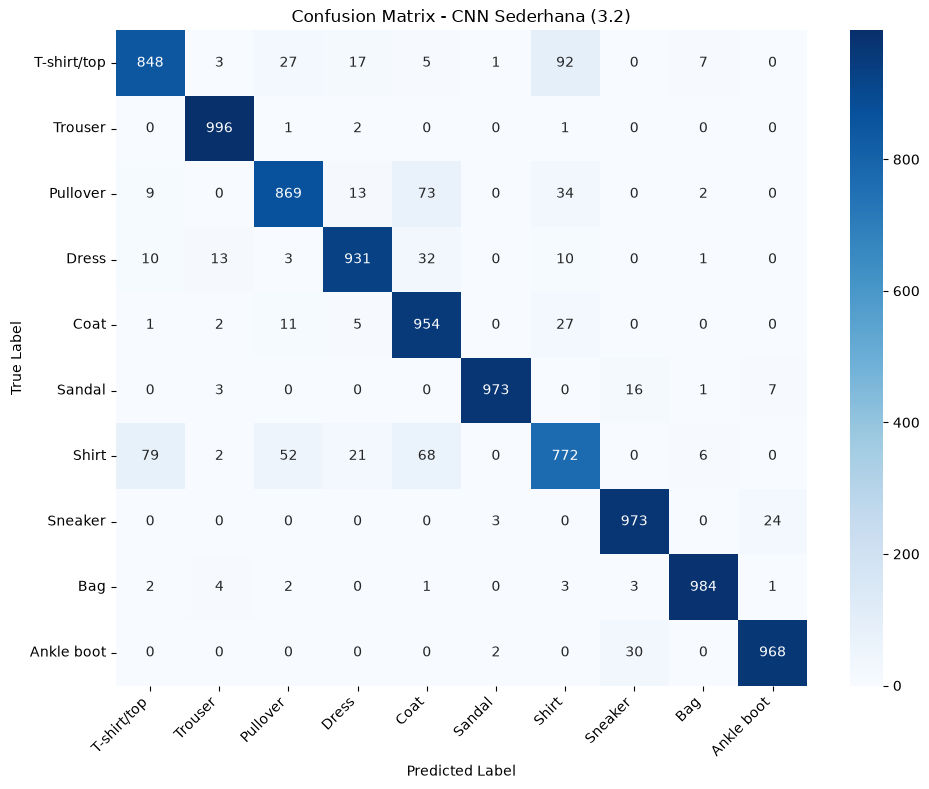

In [40]:
cm = confusion_matrix(best_true, best_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[class_names[i] for i in range(10)],
    yticklabels=[class_names[i] for i in range(10)]
)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [41]:
# Hitung pasangan kelas yang paling sering tertukar dari confusion matrix
# Hilangkan diagonal (prediksi benar)
cm_offdiag = cm.copy()
np.fill_diagonal(cm_offdiag, 0)

# Ambil 5 pasangan dengan nilai tertinggi
top_misclass = []
for i in range(10):
    for j in range(10):
        if i != j and cm_offdiag[i, j] > 0:
            top_misclass.append((class_names[i], class_names[j], cm_offdiag[i, j]))

top_misclass_sorted = sorted(top_misclass, key=lambda x: x[2], reverse=True)[:5]

print("5 pasangan kelas yang paling sering tertukar (True -> Predicted):")
for true_label, pred_label, count in top_misclass_sorted:
    print(f"  {true_label} -> {pred_label}: {count} gambar")

5 pasangan kelas yang paling sering tertukar (True -> Predicted):
  T-shirt/top -> Shirt: 92 gambar
  Shirt -> T-shirt/top: 79 gambar
  Pullover -> Coat: 73 gambar
  Shirt -> Coat: 68 gambar
  Shirt -> Pullover: 52 gambar


Jumlah gambar salah diprediksi: 732


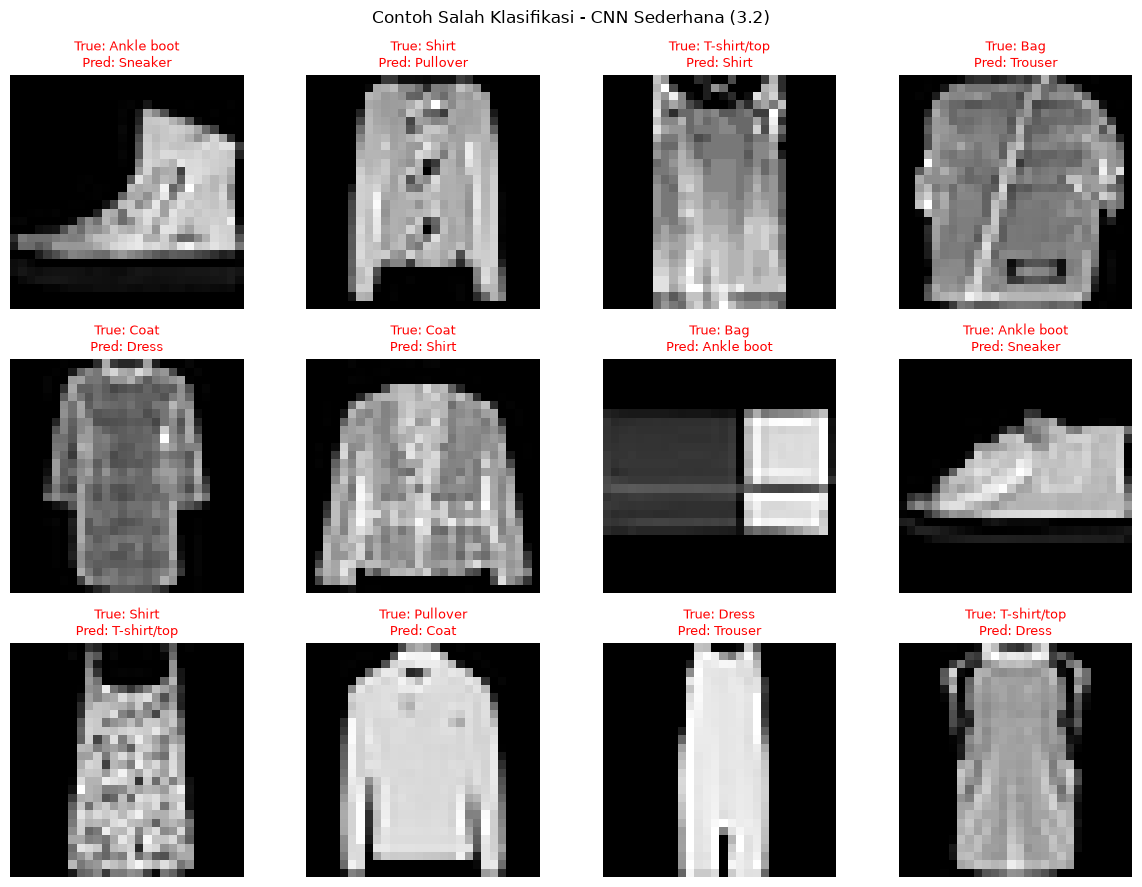

In [42]:
# Cari indeks gambar yang salah diprediksi oleh model terbaik
misclassified_idx = np.where(best_preds != best_true)[0]
print("Jumlah gambar salah diprediksi:", len(misclassified_idx))

# Pilih 12 contoh acak dengan seed agar konsisten
np.random.seed(42)
sample_idx = np.random.choice(misclassified_idx, size=12, replace=False)

# Tampilkan
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, idx in zip(axes.flatten(), sample_idx):
    img = X_test_tensor[idx].numpy().reshape(28, 28)
    ax.imshow(img, cmap='gray')
    ax.axis('off')
    ax.set_title(
        f"True: {class_names[best_true[idx]]}\nPred: {class_names[best_preds[idx]]}",
        fontsize=9, color='red'
    )
plt.suptitle(f'Contoh Salah Klasifikasi - {best_model_name}', fontsize=12)
plt.tight_layout()
plt.show()

Bentuk feature map: (32, 28, 28)


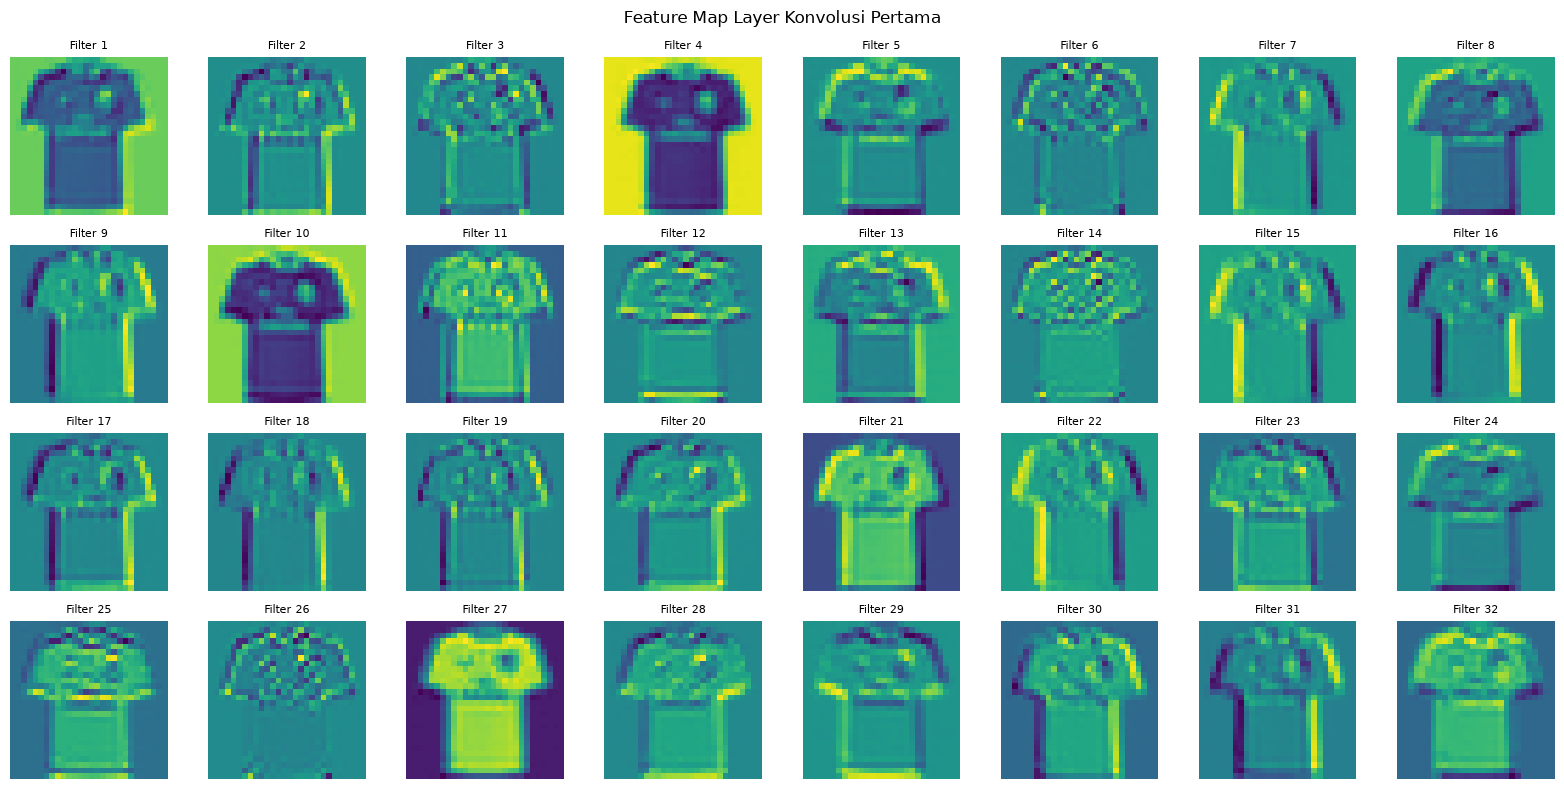

In [43]:
# Ambil satu gambar contoh dari test set
sample_img = X_test_tensor[0].unsqueeze(0).to(device)  # bentuk (1, 1, 28, 28)

# Kirim ke layer konvolusi pertama saja
best_model.eval()
with torch.no_grad():
    feature_maps = best_model.conv1(sample_img)

# feature_maps bentuknya (1, 32, 28, 28)
feature_maps = feature_maps.squeeze(0).detach().cpu().numpy()
print("Bentuk feature map:", feature_maps.shape)

# Tampilkan 32 channel
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(feature_maps[i], cmap='viridis')
    ax.axis('off')
    ax.set_title(f'Filter {i+1}', fontsize=8)
plt.suptitle('Feature Map Layer Konvolusi Pertama', fontsize=12)
plt.tight_layout()
plt.show()

In [45]:
# Simpan bobot model terbaik
torch.save(best_model.state_dict(), "model.pth")
print("Bobot model tersimpan sebagai model.pth")

# Simpan juga definisi class model terbaik agar bisa dipakai ulang saat deployment
model_definition_code = '''
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)
        return x
'''

with open("simple_cnn_model.py", "w") as f:
    f.write(model_definition_code)

print("Definisi class model tersimpan sebagai simple_cnn_model.py")

Bobot model tersimpan sebagai model.pth
Definisi class model tersimpan sebagai simple_cnn_model.py


## Analisis Bagian 4

### 1. Evaluasi Model Terbaik (CNN Sederhana 3.2)
Berdasarkan hasil pengujian pada test set, model CNN Sederhana (3.2) yang dipilih sebagai model terbaik (berdasarkan best val accuracy 0.9240) berhasil mendapatkan **Test Accuracy sebesar 0.9268** (92.68%). Nilai macro average untuk Precision, Recall, dan F1-Score juga sangat konsisten di kisaran 0.9260 hingga 0.9270, yang menunjukkan bahwa model tidak berat sebelah ke kelas mayoritas tertentu.

Jika melihat *classification report* per kelas, kelas dengan performa terbaik adalah **Trouser**, **Sandal**, dan **Bag** dengan F1-score di atas 0.98. Sebaliknya, kelas dengan performa terendah adalah **Shirt** (F1-score 0.7963) dan **T-shirt/top** (F1-score 0.8702). Rendahnya performa kelas Shirt ini sangat wajar karena kompleksitas bentuknya yang mirip dengan atasan lain.

### 2. Pasangan Kelas yang Paling Sering Tertukar
Berdasarkan output perhitungan confusion matrix, terdapat 5 pasangan kelas yang paling sering tertukar:
1. **T-shirt/top -> Shirt** (92 gambar)
2. **Shirt -> T-shirt/top** (79 gambar)
3. **Pullover -> Coat** (73 gambar)
4. **Shirt -> Coat** (68 gambar)
5. **Shirt -> Pullover** (52 gambar)

**Analisis:**
Hampir seluruh kesalahan klasifikasi terjadi pada kelompok pakaian atasan (T-shirt/top, Shirt, Pullover, Coat). Hal ini membuktikan apa yang sudah kita prediksi pada tahap Eksplorasi Data Awal (EDA): pada resolusi gambar 28x28 piksel, siluet dan tekstur dari atasan ini sangat mirip. Model kesulitan membedakan kerah, kancing, atau panjang lengan yang membedakan kemeja (Shirt) dengan kaos (T-shirt) atau sweter (Pullover) dengan mantel (Coat).

### 3. Pola pada Feature Map Layer Konvolusi Pertama
Berdasarkan visualisasi 32 filter pada layer konvolusi pertama, kita dapat mengamati beberapa pola yang ditangkap oleh model:
*   **Deteksi Tepi (Edge Detection):** Banyak filter (seperti Filter 1, 2, 7, 15, dan 19) yang menangkap garis luar atau tepi dari objek. Filter-filter ini memberikan respons tinggi (warna kuning terang) pada bagian pinggiran gambar dan lengan baju.
*   **Deteksi Kontras dan Siluet:** Beberapa filter (seperti Filter 4, 10, dan 27) menangkap siluet keseluruhan objek dengan membedakan latar belakang gelap dan objek yang lebih terang (atau sebaliknya). 
*   **Deteksi Tekstur Lokal:** Filter lain (seperti Filter 3, 11, dan 14) menangkap detail tekstur atau area dengan kontras tinggi di dalam gambar, meskipun pada resolusi 28x28 pola yang ditangkap masih terlihat kasar dan abstrak. 

Secara keseluruhan, layer konvolusi pertama berfungsi sebagai pengidentifikasi fitur tingkat rendah (low-level features) seperti batas objek, sudut, dan perubahan warna yang ekstrem, sebelum informasi ini diteruskan ke layer berikutnya untuk mengenali bentuk yang lebih kompleks.

# 5. Analisis

Berdasarkan eksperimen yang telah dilakukan, berikut adalah analisis perbandingan antara model ANN, CNN Sederhana, serta CNN dengan Batch Normalization dan Dropout.

### 1. Perbandingan Performa dan Jumlah Parameter
Berdasarkan Tabel 1, performa terbaik pada data test dipegang oleh **CNN Sederhana** dengan akurasi 92.68%, diikuti sangat dekat oleh CNN + BN + Dropout (92.54%), dan yang paling rendah adalah ANN (88.79%). 

Menariknya, ANN justru memiliki jumlah parameter paling sedikit (sekitar 235 ribu), sedangkan kedua model CNN memiliki parameter hampir dua kali lipatnya (sekitar 421 ribu). Meskipun CNN membutuhkan parameter lebih banyak, performanya jauh lebih unggul. Penambahan Batch Normalization dan Dropout pada model CNN hanya menambah sekitar 192 parameter (menjadi 421.834), jumlah yang sangat kecil dan tidak membebani model secara signifikan.

### 2. Pengaruh Cara Model Memproses Gambar
Perbedaan performa yang cukup jauh antara ANN dan CNN disebabkan oleh cara mereka memproses data gambar:
*   **ANN (Flatten):** Model ini mengubah struktur gambar 2D (28x28) menjadi deretan angka 1D (vektor 784). Karena piksel yang bersebelahan dipisahkan, ANN kehilangan informasi spasial. Model ini kesulitan mengenali pola bentuk, tepi, atau tekstur kain, sehingga hanya mengandalkan posisi piksel secara kaku.
*   **CNN (Konvolusi):** CNN memproses gambar dalam bentuk aslinya (tetap 2D). Dengan layer konvolusi, CNN mampu mengekstraksi fitur lokal seperti garis tepi baju, sudut, atau tekstur secara hierarkis. Kemampuan mengenali pola spasial inilah yang membuat CNN jauh lebih akurat dalam klasifikasi gambar dibandingkan ANN biasa.

### 3. Pengaruh Batch Normalization dan Dropout terhadap Learning Curve
Berdasarkan Tabel 2 dan Tabel 4, pengaruh Batch Normalization dan Dropout sangat terasa dalam menekan overfitting:
*   **Selisih Train dan Validation:** Pada CNN Sederhana, selisih akurasi train dan validation di epoch terakhir mencapai 4.16% (Train 96.23% vs Val 92.07%). Model ini terlihat mulai menghafal data train, terbukti dari Train Loss yang terus turun tajam hingga 0.1021, sementara Val Loss justru berfluktuasi naik (dari 0.2254 di epoch 9 menjadi 0.2373 di epoch 10).
*   **Efek Regularisasi:** Pada CNN + BN + Dropout, selisih akurasi train dan validation jauh lebih kecil, yaitu hanya 1.42% (Train 92.69% vs Val 91.27%). Train Loss tidak turun sedrastis model sebelumnya (berhenti di 0.1926), dan Val Loss relatif lebih stabil di angka 0.2235 - 0.2536. 
*   **Analisis:** Batch Normalization membantu menstabilkan proses training di setiap layer, sedangkan Dropout mencegah model terlalu bergantung pada neuron tertentu. Kombinasi ini berhasil membuat model lebih "jujur" (tidak overfit), meskipun pada eksperimen ini akurasi akhirnya sedikit lebih rendah (0.9254) dibanding CNN Sederhana yang mulai overfit (0.9268).

### 4. Kelas yang Sulit Dibedakan
Berdasarkan Tabel 3 dan data confusion matrix, kelas yang paling sulit dikenali oleh model terbaik adalah **Shirt** (F1-Score 0.7963) dan **T-shirt/top** (F1-Score 0.8702). Kelas **Pullover** (0.8845) dan **Coat** (0.8945) juga tergolong sulit.

Kesulitan ini terjadi karena keempat kelas tersebut adalah pakaian atasan yang secara visual (pada resolusi rendah 28x28) memiliki siluet yang sangat mirip. Model sering tertukar membedakan antara Shirt dengan T-shirt/top, atau Pullover dengan Coat, karena perbedaan detail seperti kerah, kancing, atau tekstur kain seringkali tidak terlihat jelas pada gambar grayscale berukuran kecil.

# 6. Kesimpulan dan Saran

### Kesimpulan
Berdasarkan seluruh rangkaian eksperimen yang telah dilakukan, dapat disimpulkan beberapa hal berikut:

1. **CNN Lebih Unggul dari ANN:** Model CNN (baik sederhana maupun dengan regularisasi) secara signifikan mengalahkan ANN dalam mengklasifikasikan Fashion-MNIST. CNN sederhana mencapai akurasi test tertinggi sebesar 92.68%, sedangkan ANN hanya mencapai 88.79%. Hal ini membuktikan bahwa kemampuan CNN dalam mempertahankan struktur spasial gambar (2D) dan mengekstraksi fitur lokal (tepi, tekstur) jauh lebih efektif dibandingkan ANN yang harus meratakan (flatten) gambar menjadi vektor 1D.

2. **Trade-off Antara Overfitting dan Akurasi:** CNN Sederhana memang memiliki akurasi test tertinggi, namun learning curve menunjukkan indikasi overfitting yang jelas (selisih train dan validation mencapai 4.16% dengan val loss yang mulai naik di akhir epoch). Di sisi lain, penambahan Batch Normalization dan Dropout berhasil menekan overfitting secara drastis (selisih train dan val turun menjadi 1.42%), meskipun harus membayar dengan sedikit penurunan akurasi test (menjadi 92.54%).

3. **Keterbatasan Visual Dataset:** Performa model terbaik masih terhambat oleh kemiripan visual antar kelas. Kelas Shirt (F1 0.7963) dan T-shirt/top (F1 0.8702) menjadi kelas yang paling sering salah diprediksi karena bentuk siluetnya yang hampir seragam pada resolusi rendah 28x28 piksel.

### Saran dan Rekomendasi

Untuk pengembangan eksperimen selanjutnya atau perbaikan model, beberapa saran yang dapat dilakukan adalah:

1. **Implementasi Early Stopping:** Pada eksperimen ini, CNN Sederhana mulai overfit pada epoch ke-8 hingga ke-10. Untuk eksperimen selanjutnya, disarankan menggunakan mekanisme *Early Stopping* berbasis nilai Validation Loss. Training akan otomatis berhenti ketika val loss tidak lagi menurun, sehingga menghemat waktu komputasi dan mencegah model menghafal data train.

2. **Tuning Hyperparameter:** Hasil eksperimen menunjukkan bahwa penambahan Dropout sebesar 0.5 membuat model CNN + BN sedikit "terlalu ragu" (underfit ringan), terlihat dari train accuracy yang hanya 92.69%. Untuk eksperimen mendatang, nilai Dropout bisa diturunkan (misalnya ke 0.3 atau 0.2) dan jumlah epoch bisa ditambah (misalnya 15-20 epoch), agar model dengan BatchNorm bisa belajar lebih dalam tanpa risiko overfit yang tinggi.

3. **Data Augmentation:** Mengingat kesulitan model membedakan kelas-kelas atasan (Shirt, T-shirt, Pullover, Coat), penambahan teknik augmentasi data seperti *Random Rotation* (rotasi kecil) atau *Random Horizontal Flip* dapat membantu model melihat variasi bentuk pakaian dari sudut pandang yang berbeda, sehingga diharapkan bisa lebih peka terhadap detail pembeda antar kelas.

4. **Persiapan Deployment:** Model terbaik (CNN Sederhana) telah disimpan dalam file `model.pth` beserta kode definisinya di `simple_cnn_model.py`. Untuk tugas Deployment ke depannya, perlu dipastikan bahwa proses *preprocessing* saat inferensi (input gambar user) harus sama persis dengan saat training, yaitu mengubah gambar ke format grayscale 28x28 dan menormalisasi nilai pikselnya ke rentang 0-1 sebelum dikonversi menjadi Tensor PyTorch.